<a href="https://colab.research.google.com/github/nmartini15/UNCC-Machine-Learning/blob/main/Noah_Martini_801294034_Homework6.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [67]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.optim as optim

from torch.utils.data import TensorDataset, DataLoader

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.linear_model import LinearRegression
from sklearn.svm import SVR

# seed for consistent results
# Set random seed for reproducible results
np.random.seed(15)
torch.manual_seed(15)


In [68]:
# Load housing dataset
housing = pd.read_csv("Housing.csv")

# Display dataset information
print("Dataset Shape:", housing.shape)
print("\nColumn Names:")
print(housing.columns)

# Display first five rows
housing.head()

Dataset Shape: (545, 13)

Column Names:
Index(['price', 'area', 'bedrooms', 'bathrooms', 'stories', 'mainroad',
       'guestroom', 'basement', 'hotwaterheating', 'airconditioning',
       'parking', 'prefarea', 'furnishingstatus'],
      dtype='object')


,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus
0,13300000,7420,4,2,3,yes,no,no,no,yes,2,yes,furnished
1,12250000,8960,4,4,4,yes,no,no,no,yes,3,no,furnished
2,12250000,9960,3,2,2,yes,no,yes,no,no,2,yes,semi-furnished
3,12215000,7500,4,2,2,yes,no,yes,no,yes,3,yes,furnished
4,11410000,7420,4,1,2,yes,yes,yes,no,yes,2,no,furnished


In [69]:
# Problem 1: Use all input features
X_p1 = housing.drop(columns=["price"]).copy()
y_p1 = housing["price"]

# Convert yes/no columns to binary
binary_columns = [
    "mainroad",
    "guestroom",
    "basement",
    "hotwaterheating",
    "airconditioning",
    "prefarea"
]

for col in binary_columns:
    X_p1[col] = X_p1[col].map({"yes": 1, "no": 0})

# Convert furnishing status to numerical values
X_p1["furnishingstatus"] = X_p1["furnishingstatus"].map({
    "unfurnished": 0,
    "semi-furnished": 1,
    "furnished": 2
})

print("Number of features:", X_p1.shape[1])
print("Features:", X_p1.columns.tolist())

# Split 80/20 into training and testing
X_train_full_p1, X_test_p1, y_train_full_p1, y_test_p1 = train_test_split(
    X_p1, y_p1, test_size=0.2, random_state=15
)

# Split training data into training and validation
X_train_p1, X_val_p1, y_train_p1, y_val_p1 = train_test_split(
    X_train_full_p1, y_train_full_p1, test_size=0.2, random_state=15
)

# Standardize features
scaler_p1 = StandardScaler()

X_train_p1 = scaler_p1.fit_transform(X_train_p1)
X_val_p1 = scaler_p1.transform(X_val_p1)
X_test_p1 = scaler_p1.transform(X_test_p1)

# Scale target values
y_train_p1 = y_train_p1.to_numpy() / 1_000_000
y_val_p1 = y_val_p1.to_numpy() / 1_000_000
y_test_p1 = y_test_p1.to_numpy() / 1_000_000

# Convert to PyTorch tensors
X_train_p1 = torch.tensor(X_train_p1, dtype=torch.float32)
X_val_p1 = torch.tensor(X_val_p1, dtype=torch.float32)
X_test_p1 = torch.tensor(X_test_p1, dtype=torch.float32)

y_train_p1 = torch.tensor(y_train_p1, dtype=torch.float32)
y_val_p1 = torch.tensor(y_val_p1, dtype=torch.float32)
y_test_p1 = torch.tensor(y_test_p1, dtype=torch.float32)

print("Training samples:", len(X_train_p1))
print("Validation samples:", len(X_val_p1))
print("Testing samples:", len(X_test_p1))

Number of features: 12
Features: ['area', 'bedrooms', 'bathrooms', 'stories', 'mainroad', 'guestroom', 'basement', 'hotwaterheating', 'airconditioning', 'parking', 'prefarea', 'furnishingstatus']
Training samples: 348
Validation samples: 88
Testing samples: 109


In [70]:
# Define fully connected neural network
# 3 hidden layers with ReLU activation

class HousingFCNN(nn.Module):
    def __init__(self):
        super(HousingFCNN, self).__init__()

        self.network = nn.Sequential(
            nn.Linear(12, 64), # 12 input neurons into 64
            nn.ReLU(),
            nn.Linear(64, 32), # 64 neurons to 32
            nn.ReLU(),
            nn.Linear(32, 16), # 32 neurons into 16
            nn.ReLU(),
            nn.Linear(16, 1) # 16 neurons to output
        )

    def forward(self, x):
        return self.network(x)

# Initialize model
model_p1 = HousingFCNN()

# Define loss function and optimizer
criterion_p1 = nn.MSELoss()
optimizer_p1 = optim.Adam(model_p1.parameters(), lr=0.001) # using Adam as optimizer

print(model_p1)

HousingFCNN(
  (network): Sequential(
    (0): Linear(in_features=12, out_features=64, bias=True)
    (1): ReLU()
    (2): Linear(in_features=64, out_features=32, bias=True)
    (3): ReLU()
    (4): Linear(in_features=32, out_features=16, bias=True)
    (5): ReLU()
    (6): Linear(in_features=16, out_features=1, bias=True)
  )
)


In [71]:
# Create training DataLoader
train_dataset_p1 = TensorDataset(X_train_p1, y_train_p1)
train_loader_p1 = DataLoader(train_dataset_p1, batch_size=32, shuffle=True)

# Training parameters
epochs_p1 = 100
train_losses_p1 = []
val_losses_p1 = []

# Training loop
for epoch in range(epochs_p1):

    model_p1.train()
    total_loss = 0

    for X_batch, y_batch in train_loader_p1:

        # Forward propagation
        predictions = model_p1(X_batch).squeeze(1)
        loss = criterion_p1(predictions, y_batch)

        # Backpropagation
        optimizer_p1.zero_grad()
        loss.backward()

        # Update weights using Adam
        optimizer_p1.step()

        total_loss += loss.item() * len(X_batch)

    # Average training loss
    train_loss = total_loss / len(X_train_p1)
    train_losses_p1.append(train_loss)

    # Validation
    model_p1.eval()

    with torch.no_grad():
        val_predictions = model_p1(X_val_p1).squeeze(1)
        val_loss = criterion_p1(val_predictions, y_val_p1)

    val_losses_p1.append(val_loss.item())

    # Print progress every 10 epochs
    if (epoch + 1) % 10 == 0:
        print(f"Epoch {epoch+1}/{epochs_p1} | "
              f"Train Loss: {train_loss:.4f} | "
              f"Validation Loss: {val_loss.item():.4f}")

Epoch 10/100 | Train Loss: 1.3437 | Validation Loss: 1.5047
Epoch 20/100 | Train Loss: 1.0805 | Validation Loss: 1.4179
Epoch 30/100 | Train Loss: 0.9690 | Validation Loss: 1.3716
Epoch 40/100 | Train Loss: 0.8841 | Validation Loss: 1.3234
Epoch 50/100 | Train Loss: 0.8248 | Validation Loss: 1.3473
Epoch 60/100 | Train Loss: 0.7537 | Validation Loss: 1.3657
Epoch 70/100 | Train Loss: 0.7007 | Validation Loss: 1.3169
Epoch 80/100 | Train Loss: 0.6268 | Validation Loss: 1.2938
Epoch 90/100 | Train Loss: 0.5601 | Validation Loss: 1.2929
Epoch 100/100 | Train Loss: 0.4938 | Validation Loss: 1.2453


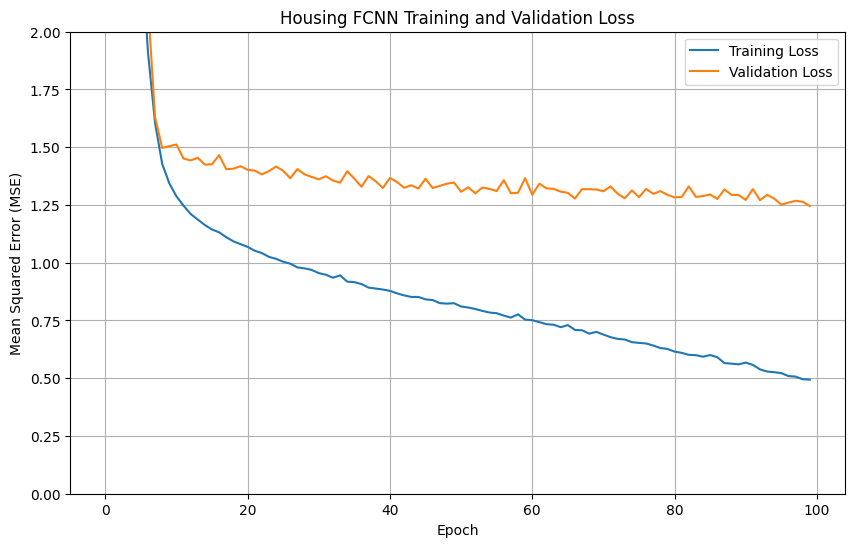

In [72]:
# Plot training and validation loss
plt.figure(figsize=(10, 6))

plt.plot(train_losses_p1, label="Training Loss")
plt.plot(val_losses_p1, label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Mean Squared Error (MSE)")
plt.title("Housing FCNN Training and Validation Loss")
plt.ylim(0, 2)
plt.legend()
plt.grid(True)
plt.show()

In [73]:
best_epoch_p1 = np.argmin(val_losses_p1) + 1
best_val_loss_p1 = min(val_losses_p1)

print("Best Epoch:", best_epoch_p1)
print("Best Validation Loss:", round(best_val_loss_p1, 4))

Best Epoch: 100
Best Validation Loss: 1.2453


In [74]:
# Problem 1.b: Traditional Machine Learning Comparison

# Recreate the original 80/20 split
X_train_ml_p1, X_test_ml_p1, y_train_ml_p1, y_test_ml_p1 = train_test_split(
    X_p1, y_p1, test_size=0.2, random_state=15
)

# Standardize input features
scaler_ml_p1 = StandardScaler()

X_train_ml_p1 = scaler_ml_p1.fit_transform(X_train_ml_p1)
X_test_ml_p1 = scaler_ml_p1.transform(X_test_ml_p1)

# Linear Regression
linear_model_p1 = LinearRegression()
linear_model_p1.fit(X_train_ml_p1, y_train_ml_p1)

linear_predictions_p1 = linear_model_p1.predict(X_test_ml_p1)

# Support Vector Regression (RBF kernel)
svr_model_p1 = SVR(kernel="rbf", C=100, epsilon=0.1)
svr_model_p1.fit(X_train_ml_p1, y_train_ml_p1 / 1_000_000)

svr_predictions_p1 = svr_model_p1.predict(X_test_ml_p1) * 1_000_000

# Calculate evaluation metrics
linear_mse_p1 = mean_squared_error(y_test_ml_p1, linear_predictions_p1)
linear_rmse_p1 = np.sqrt(linear_mse_p1)
linear_r2_p1 = r2_score(y_test_ml_p1, linear_predictions_p1)

svr_mse_p1 = mean_squared_error(y_test_ml_p1, svr_predictions_p1)
svr_rmse_p1 = np.sqrt(svr_mse_p1)
svr_r2_p1 = r2_score(y_test_ml_p1, svr_predictions_p1)

# Display results
print("Linear Regression Results")
print(f"MSE: {linear_mse_p1:,.2f}")
print(f"RMSE: ${linear_rmse_p1:,.2f}")
print(f"R²: {linear_r2_p1:.4f}")

print("\nSVR Results")
print(f"MSE: {svr_mse_p1:,.2f}")
print(f"RMSE: ${svr_rmse_p1:,.2f}")
print(f"R²: {svr_r2_p1:.4f}")

Linear Regression Results
MSE: 1,377,773,453,570.33
RMSE: $1,173,785.95
R²: 0.6365

SVR Results
MSE: 2,031,276,738,321.92
RMSE: $1,425,228.66
R²: 0.4641


In [75]:
# Problem 1: Final FCNN training using full 80% training dataset

# Use standardized data from Problem 1.b
X_train_final_p1 = torch.tensor(X_train_ml_p1, dtype=torch.float32)
X_test_final_p1 = torch.tensor(X_test_ml_p1, dtype=torch.float32)

# Scale target values
y_train_final_p1 = torch.tensor(
    y_train_ml_p1.to_numpy() / 1_000_000,
    dtype=torch.float32
)

# Create DataLoader
train_dataset_final_p1 = TensorDataset(
    X_train_final_p1, y_train_final_p1
)

train_loader_final_p1 = DataLoader(
    train_dataset_final_p1,
    batch_size=32,
    shuffle=True
)

# Initialize new model
model_final_p1 = HousingFCNN()

criterion_final_p1 = nn.MSELoss()
optimizer_final_p1 = optim.Adam(
    model_final_p1.parameters(),
    lr=0.001
)

# Train using the best epoch from validation
for epoch in range(best_epoch_p1):

    model_final_p1.train()

    for X_batch, y_batch in train_loader_final_p1:

        predictions = model_final_p1(X_batch).squeeze(1)
        loss = criterion_final_p1(predictions, y_batch)

        optimizer_final_p1.zero_grad()
        loss.backward()
        optimizer_final_p1.step()

# Evaluate final model
model_final_p1.eval()

with torch.no_grad():
    predictions_final_p1 = model_final_p1(X_test_final_p1).squeeze(1)

# Convert predictions back to dollars
predictions_final_p1 = predictions_final_p1.numpy() * 1_000_000

# Calculate final metrics
mse_final_p1 = mean_squared_error(
    y_test_ml_p1, predictions_final_p1
)

rmse_final_p1 = np.sqrt(mse_final_p1)

r2_final_p1 = r2_score(
    y_test_ml_p1, predictions_final_p1
)

print("Final FCNN Test Results")
print(f"MSE: {mse_final_p1:,.2f}")
print(f"RMSE: ${rmse_final_p1:,.2f}")
print(f"R² Score: {r2_final_p1:.4f}")

Final FCNN Test Results
MSE: 1,576,390,098,944.00
RMSE: $1,255,543.75
R² Score: 0.5841


In [76]:
# Final comparison of all three models
comparison_p1 = pd.DataFrame({
    "Model": ["FCNN", "Linear Regression", "SVR (RBF)"],
    "MSE": [mse_final_p1, linear_mse_p1, svr_mse_p1],
    "RMSE": [rmse_final_p1, linear_rmse_p1, svr_rmse_p1],
    "R²": [r2_final_p1, linear_r2_p1, svr_r2_p1]
})

comparison_p1

,Model,MSE,RMSE,R²
0,FCNN,1.576390e+12,1.255544e+06,0.584074
1,Linear Regression,1.377773e+12,1.173786e+06,0.636478
2,SVR (RBF),2.031277e+12,1.425229e+06,0.464053


In [77]:
# Problem 2: Breast Cancer Classification

# Load cancer dataset
cancer = pd.read_csv("Cancer.csv")

print("Dataset Shape:", cancer.shape)
print("\nColumn Names:")
print(cancer.columns)

cancer.head()

Dataset Shape: (569, 33)

Column Names:
Index(['id', 'diagnosis', 'radius_mean', 'texture_mean', 'perimeter_mean',
       'area_mean', 'smoothness_mean', 'compactness_mean', 'concavity_mean',
       'concave points_mean', 'symmetry_mean', 'fractal_dimension_mean',
       'radius_se', 'texture_se', 'perimeter_se', 'area_se', 'smoothness_se',
       'compactness_se', 'concavity_se', 'concave points_se', 'symmetry_se',
       'fractal_dimension_se', 'radius_worst', 'texture_worst',
       'perimeter_worst', 'area_worst', 'smoothness_worst',
       'compactness_worst', 'concavity_worst', 'concave points_worst',
       'symmetry_worst', 'fractal_dimension_worst', 'Unnamed: 32'],
      dtype='object')


,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,...,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst,Unnamed: 32
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,NaN
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,NaN
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,NaN
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,NaN
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,NaN


In [78]:
# Problem 2: Data Preprocessing

# Separate features and target
X_p2 = cancer.drop(columns=["id", "diagnosis", "Unnamed: 32"])
y_p2 = cancer["diagnosis"].map({"B": 0, "M": 1})

# Check for missing values
print("Missing values:", X_p2.isnull().sum().sum())

# Check target distribution
print("\nDiagnosis counts:")
print(y_p2.value_counts())

print("\nNumber of features:", X_p2.shape[1])

Missing values: 0

Diagnosis counts:
diagnosis
0    357
1    212
Name: count, dtype: int64

Number of features: 30


In [79]:
# Problem 2: Split and Standardize Data

# Split into 80% training and 20% testing
X_train_p2, X_test_p2, y_train_p2, y_test_p2 = train_test_split(
    X_p2, y_p2,
    test_size=0.2,
    random_state=15,
    stratify=y_p2 # stratify keeps proportions of malignant/benign roughly equal between the 2 sets
)

# Split training data into training and validation sets
X_train_sub_p2, X_val_p2, y_train_sub_p2, y_val_p2 = train_test_split(
    X_train_p2, y_train_p2,
    test_size=0.2,
    random_state=15,
    stratify=y_train_p2 # stratify keeps proportions of malignant/benign roughly equal between the 2 sets
)

# Standardize using training data only
scaler_p2 = StandardScaler()

X_train_sub_scaled_p2 = scaler_p2.fit_transform(X_train_sub_p2)
X_val_scaled_p2 = scaler_p2.transform(X_val_p2)

# Print dataset sizes
print("Training samples:", len(X_train_sub_p2))
print("Validation samples:", len(X_val_p2))
print("Testing samples:", len(X_test_p2))

Training samples: 364
Validation samples: 91
Testing samples: 114


In [80]:
# Problem 2: Build FCNN

class CancerFCNN(nn.Module):
    def __init__(self):
        super().__init__()

        # similar architecture to problem 1: 3 hidden layers
        # using ReLU as activation and Adam as optimizer
        self.network = nn.Sequential(
            nn.Linear(30, 64), # 30 input neurons to 64
            nn.ReLU(),
            nn.Linear(64, 32), # 64 neurons to 32
            nn.ReLU(),
            nn.Linear(32, 16), # 32 neurons to 16
            nn.ReLU(),
            nn.Linear(16, 1) # 16 neurons to output
        )

    def forward(self, x):
        return self.network(x)


model_p2 = CancerFCNN()

# Loss function and optimizer
criterion_p2 = nn.BCEWithLogitsLoss()
optimizer_p2 = torch.optim.Adam(model_p2.parameters(), lr=0.001)

print(model_p2)

CancerFCNN(
  (network): Sequential(
    (0): Linear(in_features=30, out_features=64, bias=True)
    (1): ReLU()
    (2): Linear(in_features=64, out_features=32, bias=True)
    (3): ReLU()
    (4): Linear(in_features=32, out_features=16, bias=True)
    (5): ReLU()
    (6): Linear(in_features=16, out_features=1, bias=True)
  )
)


In [81]:
# Problem 2: Convert data to PyTorch tensors

X_train_tensor_p2 = torch.tensor(X_train_sub_scaled_p2, dtype=torch.float32)
y_train_tensor_p2 = torch.tensor(y_train_sub_p2.to_numpy(), dtype=torch.float32).view(-1, 1)

X_val_tensor_p2 = torch.tensor(X_val_scaled_p2, dtype=torch.float32)
y_val_tensor_p2 = torch.tensor(y_val_p2.to_numpy(), dtype=torch.float32).view(-1, 1)

# Create training DataLoader
train_dataset_p2 = TensorDataset(X_train_tensor_p2, y_train_tensor_p2)
train_loader_p2 = DataLoader(train_dataset_p2, batch_size=32, shuffle=True)

In [82]:
# Problem 2: Train FCNN

train_losses_p2 = []
val_losses_p2 = []

train_accuracies_p2 = []
val_accuracies_p2 = []

for epoch in range(100):

    # Training
    model_p2.train()
    total_loss = 0

    for X_batch, y_batch in train_loader_p2:
        optimizer_p2.zero_grad()

        predictions = model_p2(X_batch)
        loss = criterion_p2(predictions, y_batch)

        loss.backward()
        optimizer_p2.step()

        total_loss += loss.item() * len(X_batch)

    avg_train_loss = total_loss / len(train_dataset_p2)
    train_losses_p2.append(avg_train_loss)

    # Validation
    model_p2.eval()

    with torch.no_grad():
        val_predictions = model_p2(X_val_tensor_p2)
        val_loss = criterion_p2(val_predictions, y_val_tensor_p2)

    val_losses_p2.append(val_loss.item())

    if (epoch + 1) % 10 == 0:
        print(
            f"Epoch {epoch+1}/100 | "
            f"Train Loss: {avg_train_loss:.4f} | "
            f"Val Loss: {val_loss.item():.4f}"
        )

    # Calculate training and validation accuracy
    model_p2.eval()

    with torch.no_grad():
        train_logits = model_p2(X_train_tensor_p2)
        train_preds = (torch.sigmoid(train_logits) >= 0.5).float()

        val_logits = model_p2(X_val_tensor_p2)
        val_preds = (torch.sigmoid(val_logits) >= 0.5).float()

        train_accuracy = (train_preds == y_train_tensor_p2).float().mean().item()
        val_accuracy = (val_preds == y_val_tensor_p2).float().mean().item()

    train_accuracies_p2.append(train_accuracy)
    val_accuracies_p2.append(val_accuracy)

Epoch 10/100 | Train Loss: 0.1031 | Val Loss: 0.0814
Epoch 20/100 | Train Loss: 0.0405 | Val Loss: 0.0826
Epoch 30/100 | Train Loss: 0.0185 | Val Loss: 0.1060
Epoch 40/100 | Train Loss: 0.0068 | Val Loss: 0.1330
Epoch 50/100 | Train Loss: 0.0024 | Val Loss: 0.1652
Epoch 60/100 | Train Loss: 0.0012 | Val Loss: 0.1862
Epoch 70/100 | Train Loss: 0.0007 | Val Loss: 0.1991
Epoch 80/100 | Train Loss: 0.0005 | Val Loss: 0.2135
Epoch 90/100 | Train Loss: 0.0003 | Val Loss: 0.2200
Epoch 100/100 | Train Loss: 0.0003 | Val Loss: 0.2292


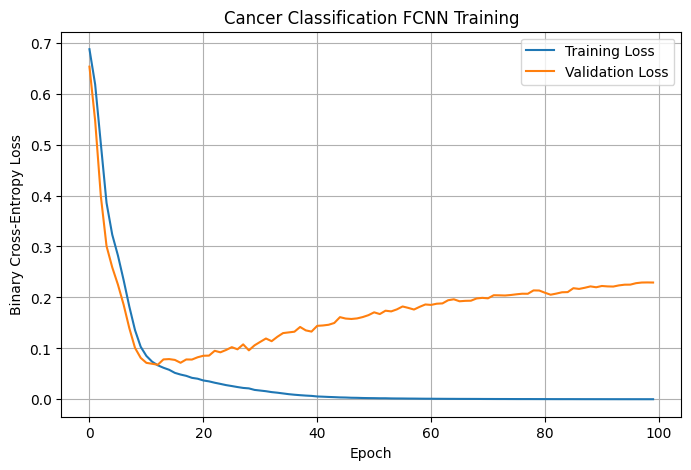

Best validation epoch: 13
Lowest validation loss: 0.06790300458669662


In [83]:
# Problem 2: Plot training and validation loss

plt.figure(figsize=(8, 5))

plt.plot(train_losses_p2, label="Training Loss")
plt.plot(val_losses_p2, label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Binary Cross-Entropy Loss")
plt.title("Cancer Classification FCNN Training")
plt.legend()
plt.grid(True)

plt.show()

# Find epoch with lowest validation loss
best_epoch_p2 = np.argmin(val_losses_p2) + 1

print("Best validation epoch:", best_epoch_p2)
print("Lowest validation loss:", min(val_losses_p2))

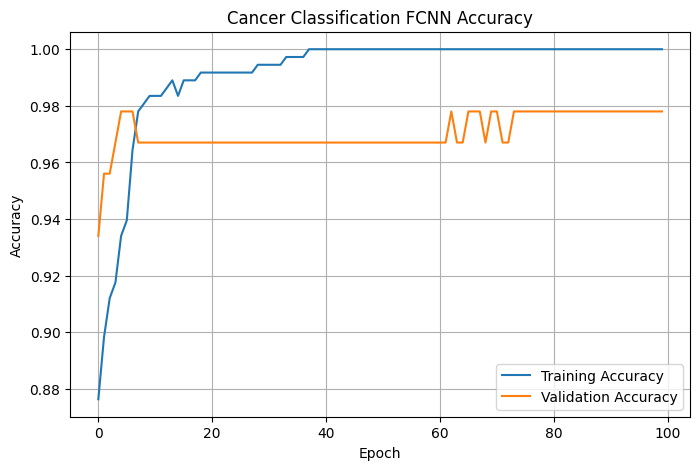

In [84]:
# Problem 2: Plot classification accuracy over epochs

plt.figure(figsize=(8, 5))

plt.plot(train_accuracies_p2, label="Training Accuracy")
plt.plot(val_accuracies_p2, label="Validation Accuracy")

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Cancer Classification FCNN Accuracy")
plt.legend()
plt.grid(True)

plt.show()

In [85]:
# Problem 2: Final FCNN Training and Evaluation

# Standardize full training and test data
final_scaler_p2 = StandardScaler()

X_train_final_scaled_p2 = final_scaler_p2.fit_transform(X_train_p2)
X_test_final_scaled_p2 = final_scaler_p2.transform(X_test_p2)

# Convert to tensors
X_train_final_tensor_p2 = torch.tensor(
    X_train_final_scaled_p2, dtype=torch.float32
)

y_train_final_tensor_p2 = torch.tensor(
    y_train_p2.to_numpy(), dtype=torch.float32
).view(-1, 1)

X_test_tensor_p2 = torch.tensor(
    X_test_final_scaled_p2, dtype=torch.float32
)

# Create DataLoader
final_dataset_p2 = TensorDataset(
    X_train_final_tensor_p2,
    y_train_final_tensor_p2
)

final_loader_p2 = DataLoader(
    final_dataset_p2,
    batch_size=32,
    shuffle=True
)

# Create a fresh model
final_model_p2 = CancerFCNN()

final_optimizer_p2 = torch.optim.Adam(
    final_model_p2.parameters(),
    lr=0.001
)

# Train using best validation epoch
for epoch in range(best_epoch_p2):
    final_model_p2.train()

    for X_batch, y_batch in final_loader_p2:
        final_optimizer_p2.zero_grad()

        predictions = final_model_p2(X_batch)
        loss = criterion_p2(predictions, y_batch)

        loss.backward()
        final_optimizer_p2.step()

# Evaluate on test data
final_model_p2.eval()

with torch.no_grad():
    test_logits_p2 = final_model_p2(X_test_tensor_p2)
    test_probs_p2 = torch.sigmoid(test_logits_p2)
    test_preds_p2 = (test_probs_p2 >= 0.5).int().numpy().flatten()

# Classification metrics
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

fcnn_accuracy_p2 = accuracy_score(y_test_p2, test_preds_p2)
fcnn_precision_p2 = precision_score(y_test_p2, test_preds_p2)
fcnn_recall_p2 = recall_score(y_test_p2, test_preds_p2)
fcnn_f1_p2 = f1_score(y_test_p2, test_preds_p2)

print("FCNN Test Results")
print("Accuracy:", round(fcnn_accuracy_p2, 4))
print("Precision:", round(fcnn_precision_p2, 4))
print("Recall:", round(fcnn_recall_p2, 4))
print("F1 Score:", round(fcnn_f1_p2, 4))

FCNN Test Results
Accuracy: 0.9737
Precision: 1.0
Recall: 0.9286
F1 Score: 0.963


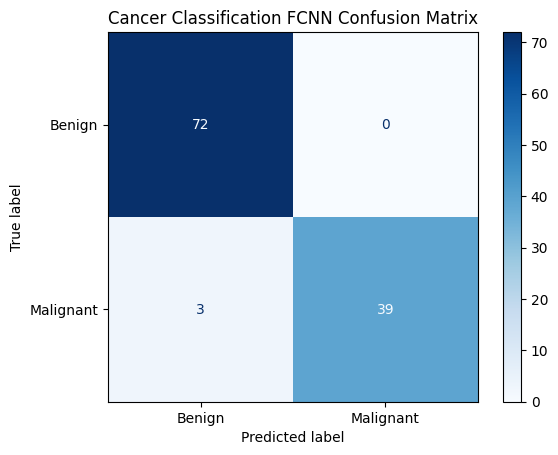

In [86]:
# Problem 2: FCNN Confusion Matrix

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm_p2 = confusion_matrix(y_test_p2, test_preds_p2)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_p2,
    display_labels=["Benign", "Malignant"]
)

disp.plot(cmap="Blues")
plt.title("Cancer Classification FCNN Confusion Matrix")
plt.show()

In [87]:
# Problem 2: Logistic Regression and SVM Comparison

from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC

# Logistic Regression
logistic_model_p2 = LogisticRegression(max_iter=1000)
logistic_model_p2.fit(X_train_final_scaled_p2, y_train_p2)

logistic_preds_p2 = logistic_model_p2.predict(X_test_final_scaled_p2)

logistic_accuracy_p2 = accuracy_score(y_test_p2, logistic_preds_p2)
logistic_precision_p2 = precision_score(y_test_p2, logistic_preds_p2)
logistic_recall_p2 = recall_score(y_test_p2, logistic_preds_p2)
logistic_f1_p2 = f1_score(y_test_p2, logistic_preds_p2)

# Support Vector Machine (RBF kernel)
svm_model_p2 = SVC(kernel="rbf")
svm_model_p2.fit(X_train_final_scaled_p2, y_train_p2)

svm_preds_p2 = svm_model_p2.predict(X_test_final_scaled_p2)

svm_accuracy_p2 = accuracy_score(y_test_p2, svm_preds_p2)
svm_precision_p2 = precision_score(y_test_p2, svm_preds_p2)
svm_recall_p2 = recall_score(y_test_p2, svm_preds_p2)
svm_f1_p2 = f1_score(y_test_p2, svm_preds_p2)

print("Logistic Regression Results")
print("Accuracy:", round(logistic_accuracy_p2, 4))
print("Precision:", round(logistic_precision_p2, 4))
print("Recall:", round(logistic_recall_p2, 4))
print("F1:", round(logistic_f1_p2, 4))

print("\nSVM Results")
print("Accuracy:", round(svm_accuracy_p2, 4))
print("Precision:", round(svm_precision_p2, 4))
print("Recall:", round(svm_recall_p2, 4))
print("F1:", round(svm_f1_p2, 4))

Logistic Regression Results
Accuracy: 0.9737
Precision: 1.0
Recall: 0.9286
F1: 0.963

SVM Results
Accuracy: 0.9825
Precision: 1.0
Recall: 0.9524
F1: 0.9756


In [88]:
# Problem 2: Final Model Comparison

comparison_p2 = pd.DataFrame({
    "Model": ["FCNN", "Logistic Regression", "SVM (RBF)"],
    "Accuracy": [fcnn_accuracy_p2, logistic_accuracy_p2, svm_accuracy_p2],
    "Precision": [fcnn_precision_p2, logistic_precision_p2, svm_precision_p2],
    "Recall": [fcnn_recall_p2, logistic_recall_p2, svm_recall_p2],
    "F1 Score": [fcnn_f1_p2, logistic_f1_p2, svm_f1_p2]
})

comparison_p2

,Model,Accuracy,Precision,Recall,F1 Score
0,FCNN,0.973684,1.0,0.928571,0.962963
1,Logistic Regression,0.973684,1.0,0.928571,0.962963
2,SVM (RBF),0.982456,1.0,0.952381,0.975610
